Componentes conexos nas imagens de exemplo

---

Bibliotecas

In [316]:
import cv2

import matplotlib.pyplot as plt
import networkx          as nx
import numpy             as np

from collections import deque


---

Carregando a imagem do Josefran

In [317]:
josefran_image = cv2.imread("../../assets/josefran.jpg")
josefran_image = cv2.cvtColor(josefran_image, cv2.COLOR_BGR2GRAY)

josefran_image.shape

(640, 640)

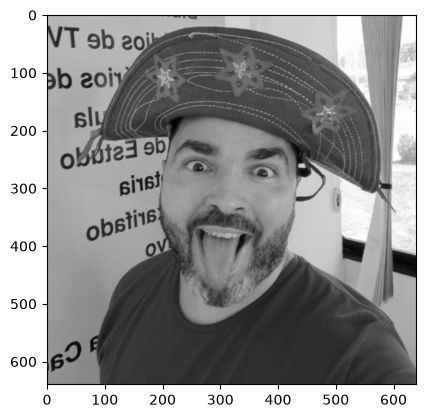

In [318]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [319]:
josefran_image = cv2.resize(josefran_image, (64, 64), cv2.INTER_LINEAR)
josefran_image.shape

(64, 64)

Visualização da imagem final

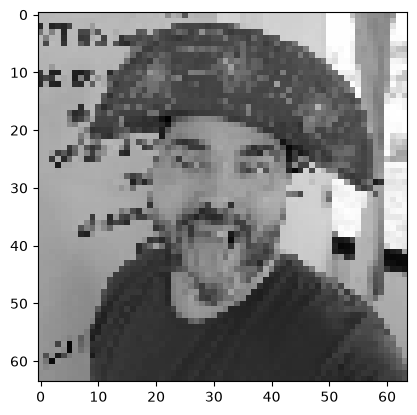

In [320]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

---

Carregando a imagem de um ave

In [321]:
ave_image = cv2.imread("../../assets/ave.jpg")
ave_image = cv2.cvtColor(ave_image, cv2.COLOR_BGR2GRAY)

ave_image.shape

(3874, 4128)

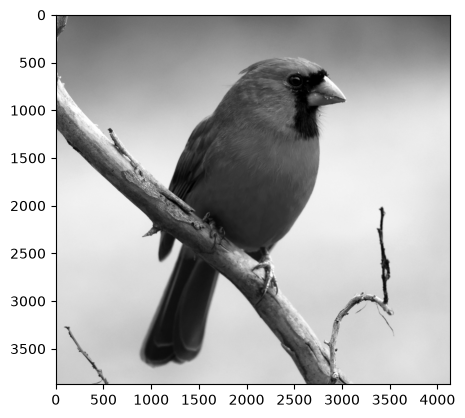

In [322]:
plt.imshow(ave_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [323]:
ave_image = cv2.resize(ave_image, (64, 64), cv2.INTER_LINEAR)
ave_image.shape

(64, 64)

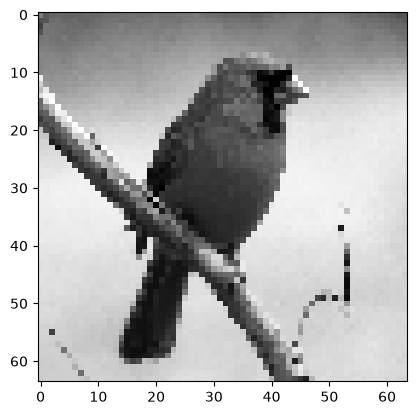

In [324]:
plt.imshow(ave_image, cmap='gray')
plt.show()

Visualização da imagem final

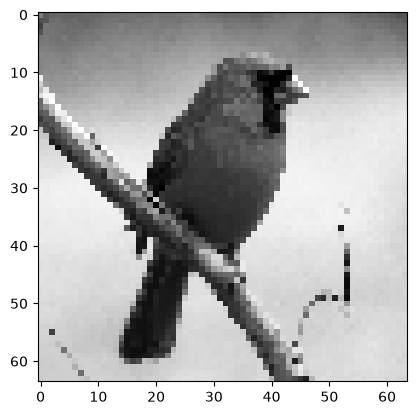

In [325]:
plt.imshow(ave_image, cmap='gray')
plt.show()

---

Carregando a imagem de meme

In [326]:
meme_image = cv2.imread("../../assets/meme.jpg")
meme_image = cv2.cvtColor(meme_image, cv2.COLOR_BGR2GRAY)

meme_image.shape

(598, 598)

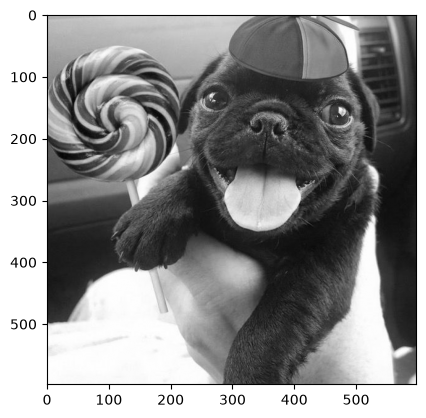

In [327]:
plt.imshow(meme_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [328]:
meme_image = cv2.resize(meme_image, (64, 64), cv2.INTER_LINEAR)
meme_image.shape

(64, 64)

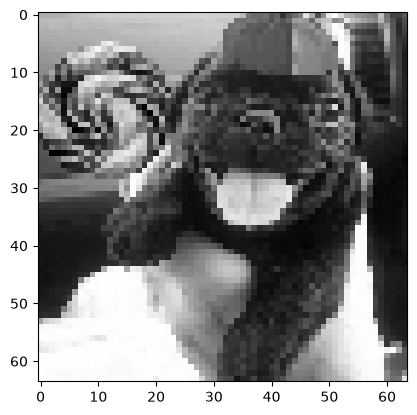

In [329]:
plt.imshow(meme_image, cmap='gray')
plt.show()

Visualização da imagem final

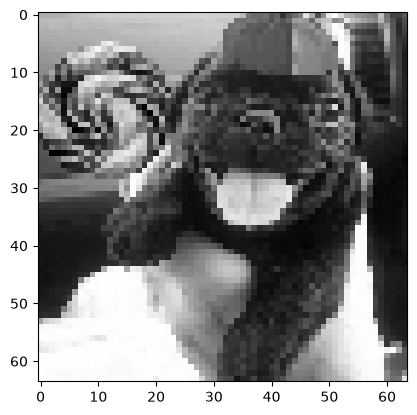

In [330]:
plt.imshow(meme_image, cmap='gray')
plt.show()

---

Algoritmo para construir a representação em grafos de uma imagem

In [331]:
def construir_grafo_imagem(matriz_pixels, vizinhanca=4, limiar=10):
    altura, largura = matriz_pixels.shape
    grafo           = { (i, j): [] for i in range(altura) for j in range(largura) }
    
    # Definir deslocamentos com base na vizinhança
    if vizinhanca == 4:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    elif vizinhanca == 8:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1), 
                    (-1, -1), (-1, 1), (1, -1), (1, 1)]
    else:
        raise ValueError("A vizinhança deve ser 4 ou 8.")

    for i in range(altura):
        for j in range(largura):
            u = (i, j)
            intensidade_u = matriz_pixels[i, j]
            
            for di, dj in direcoes:
                ni, nj = i + di, j + dj
                
                if 0 <= ni < altura and 0 <= nj < largura:
                    v = (ni, nj)
                    intensidade_v = matriz_pixels[ni, nj]
                    
                    if abs(int(intensidade_u) - int(intensidade_v)) <= limiar:
                        grafo[u].append(v)
                        
    return grafo

---

Algoritmo para encontrar as componentes conexas

In [332]:
def dfs_componentes_conexas(grafo):
    visitados = set()
    componentes = []

    for pixel_inicial in grafo:
        if pixel_inicial not in visitados:
            # Inicia uma nova componente conexa
            pixels_componente = []
            fila = deque([pixel_inicial])
            visitados.add(pixel_inicial)

            while fila:
                u = fila.popleft()
                pixels_componente.append(u)

                for v in grafo[u]:
                    if v not in visitados:
                        visitados.add(v)
                        fila.append(v)

            componentes.append({
                'tamanho': len(pixels_componente),
                'pixels': pixels_componente
            })

    # Ordena da maior componente para a menor
    componentes.sort(key=lambda c: c['tamanho'], reverse=True)

    # Atribui um ID sequencial (0 = maior componente)
    for idx, comp in enumerate(componentes):
        comp['id'] = idx

    return componentes

---

Gerando os grafos

In [333]:
josefran_graph = construir_grafo_imagem(josefran_image, vizinhanca = 4, limiar = 10)
meme_graph     = construir_grafo_imagem(meme_image, vizinhanca = 4, limiar = 10)
ave_graph      = construir_grafo_imagem(ave_image, vizinhanca = 4, limiar = 10)

---

Encontrando as componentes conexas

In [334]:
josefran_comp_conexas = dfs_componentes_conexas(josefran_graph)
meme_comp_conexas     = dfs_componentes_conexas(meme_graph)
ave_comp_conexas      = dfs_componentes_conexas(ave_graph)

---

Visualizando as componentes conexas

In [335]:
def visualizar_componentes_dfs_grid(itens, tamanho_minimo=1, seed=42):
    """
    Gera um único plot 2x3 com as 3 imagens na linha 0 e suas
    componentes conexas coloridas na linha 1.

    `itens` deve ser uma lista com 3 tuplas:
        (nome, matriz_pixels, componentes)
    """
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    rng = np.random.default_rng(seed)

    for col, (nome, matriz_pixels, componentes) in enumerate(itens):
        altura, largura = matriz_pixels.shape
        imagem_colorida = np.zeros((altura, largura, 3), dtype=np.uint8)

        exibidas = 0
        for comp in componentes:
            if comp["tamanho"] >= tamanho_minimo:
                # Gera cor RGB entre 40 e 255 para destacar do fundo preto
                cor = rng.integers(40, 256, size=3, dtype=np.uint8)
                for i, j in comp["pixels"]:
                    imagem_colorida[i, j] = cor
                exibidas += 1

        # Linha 0: Imagem original
        ax_orig = axes[0, col]
        ax_orig.imshow(matriz_pixels, cmap="gray", vmin=0, vmax=255)
        ax_orig.set_title(f"{nome} — Original ({altura}x{largura})")
        ax_orig.axis("off")

        # Linha 1: Componentes conexas
        ax_comp = axes[1, col]
        ax_comp.imshow(imagem_colorida)
        ax_comp.set_title(
            f"{nome} — Componentes ({exibidas}/{len(componentes)} | mín={tamanho_minimo} px)"
        )
        ax_comp.axis("off")

    plt.tight_layout()
    plt.show()


In [336]:
itens_visualizacao = [
    ("Josefran", josefran_image, josefran_comp_conexas),
    ("Meme", meme_image, meme_comp_conexas),
    ("Ave", ave_image, ave_comp_conexas),
]

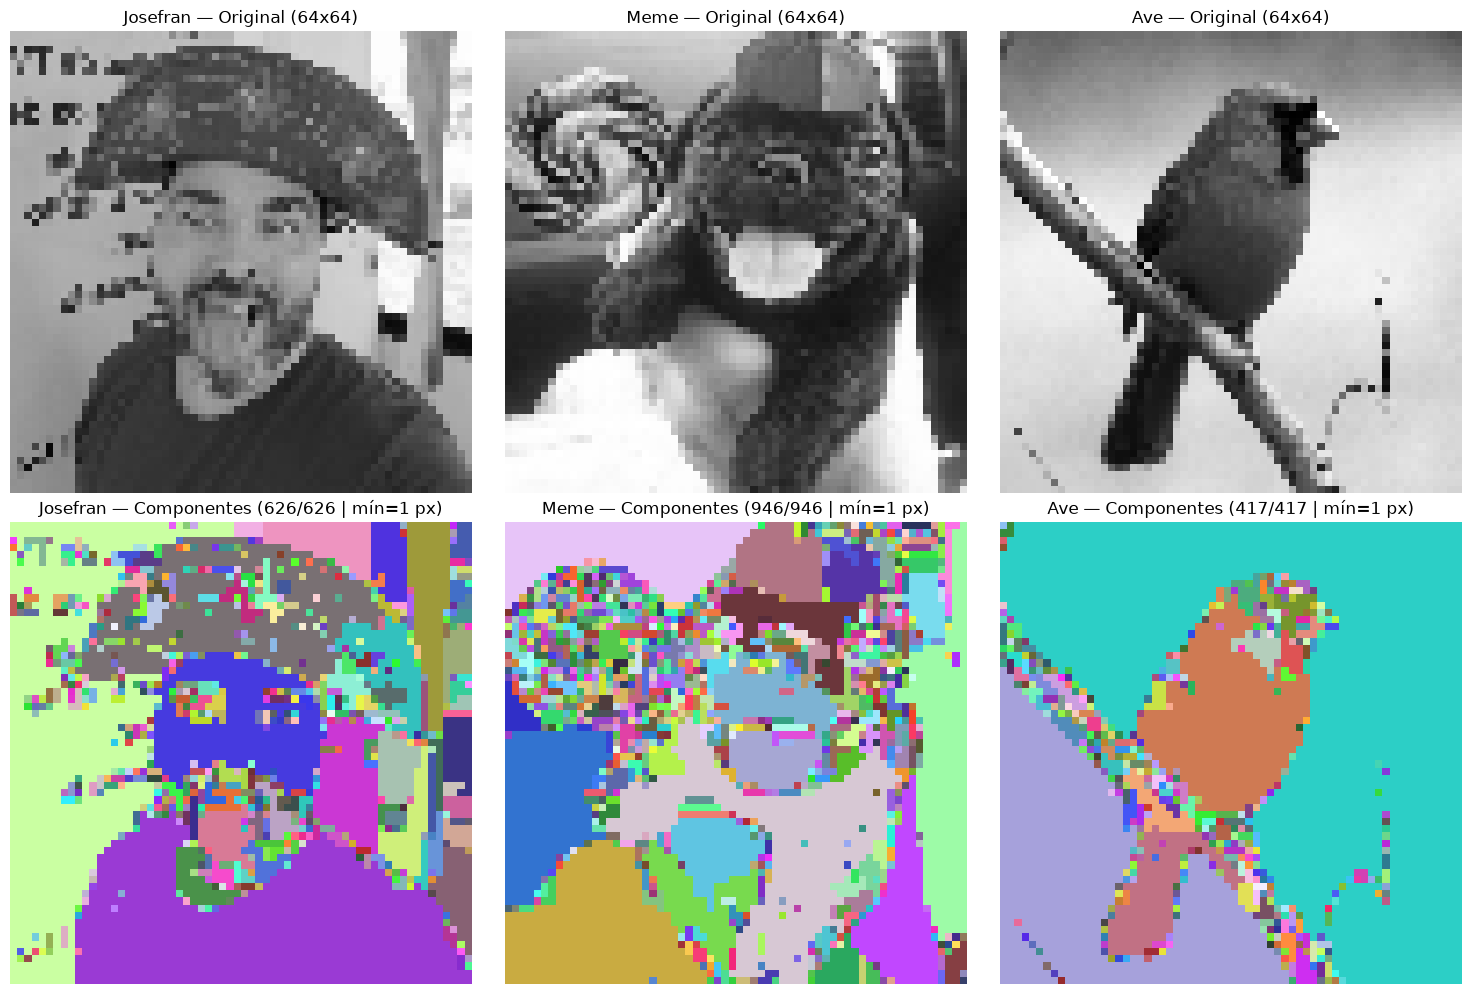

In [337]:
visualizar_componentes_dfs_grid(itens_visualizacao, tamanho_minimo=1, seed=42)

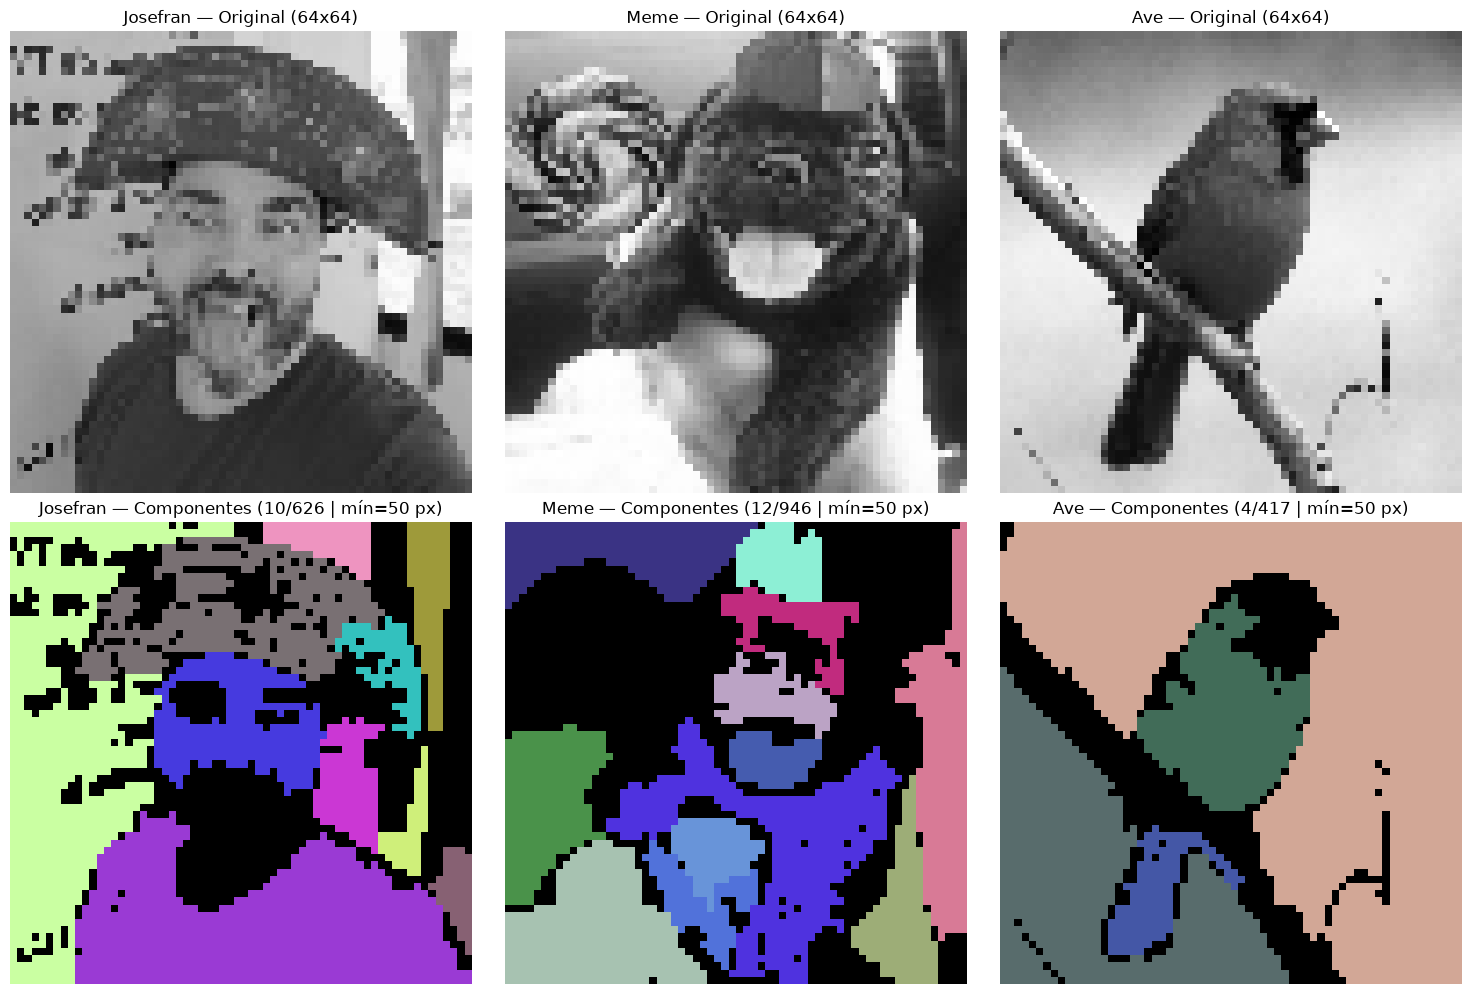

In [338]:
visualizar_componentes_dfs_grid(itens_visualizacao, tamanho_minimo=50, seed=42)

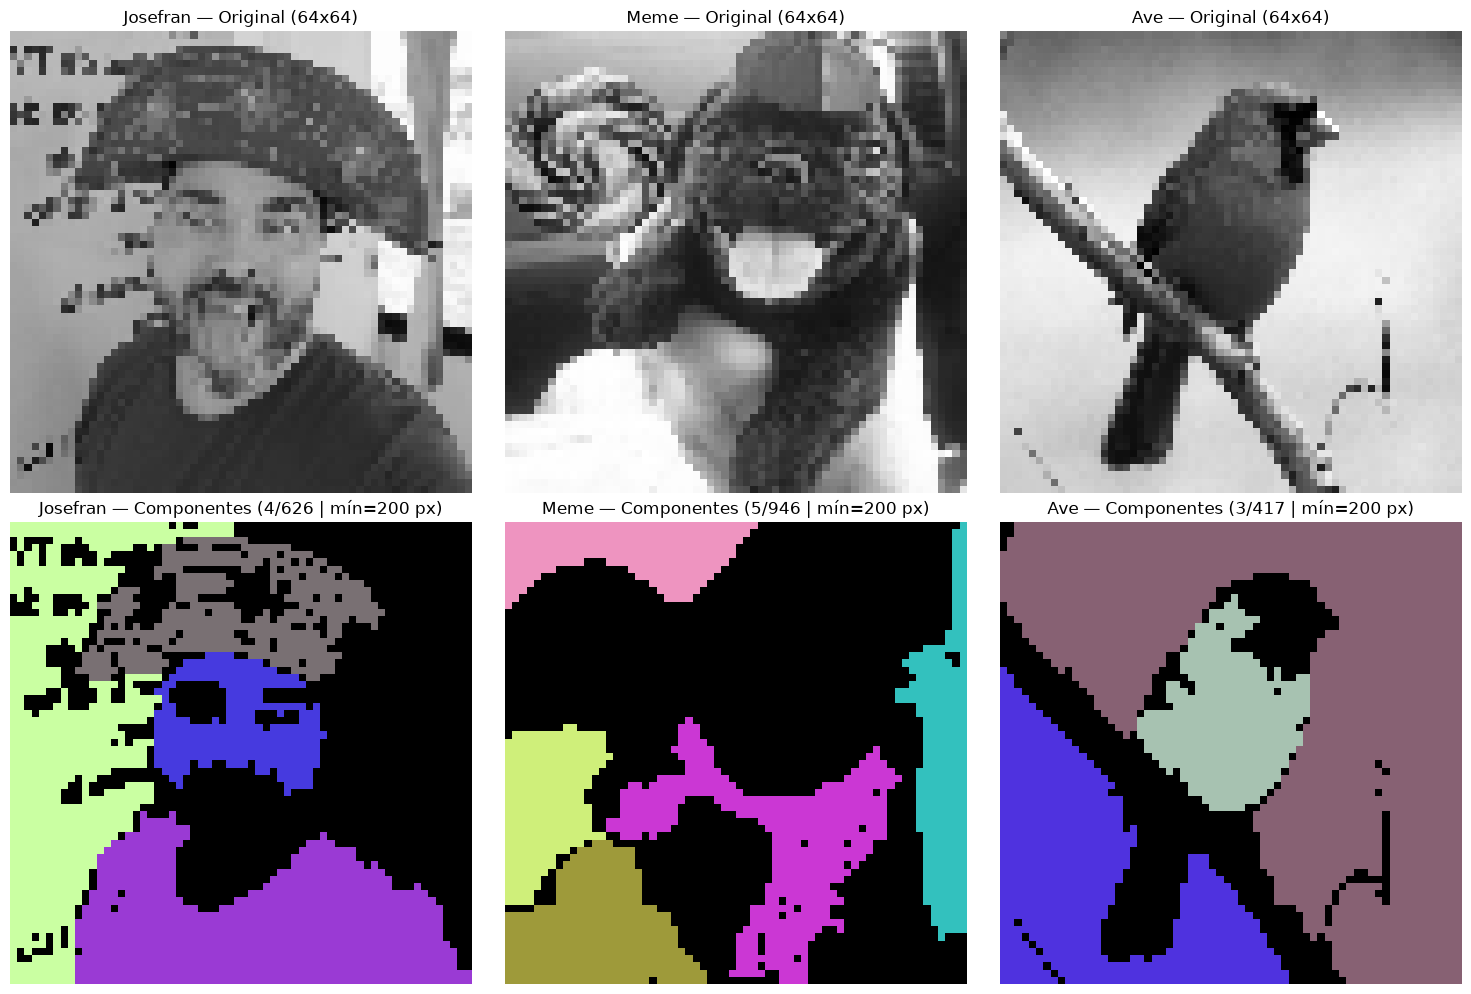

In [339]:
visualizar_componentes_dfs_grid(itens_visualizacao, tamanho_minimo=200, seed=42)